# DermaScan: pembuatan model HistGradientBoosting

Notebook ini membuat ulang **model terbaik yang sudah ditentukan**:
`skin_spatial_histgb_15`. Tidak ada pencarian parameter atau seleksi model.

Alur: **ACNE04 → audit gambar → split yang sama → fitur skin_spatial
→ satu pelatihan HistGradientBoosting → evaluasi test → simpan → prediksi severity**.

Agar hasil mengikuti model sebelumnya, notebook mempertahankan revisi dataset,
aturan pembersihan, urutan baris training, 6.259 fitur, parameter model,
seed 42, dan versi library. Model akhir dilatih pada **training lalu validation**,
persis seperti tahap refit pada notebook optimasi. Data test tidak ikut dilatih.

Jalankan sel dari atas ke bawah menggunakan CPU. Gambar sekitar 1,13 GB dan
ekstraksi fitur dapat memerlukan beberapa menit hingga puluhan menit.
Notebook berisi seluruh kode yang diperlukan; tidak perlu menjalankan notebook lama.
Semua berkas baru disimpan di `hasil_dermascan_histgb`.

## 1. Instalasi library

Versi komputasi disamakan dengan lingkungan model referensi (Python 3.10.6).
Jika paket sudah sesuai, sel instalasi dapat dilewati. Setelah mengganti versi
paket dalam kernel yang aktif, restart kernel/runtime lalu lanjutkan dari sel import.
`datasets` digunakan saat mengunduh dari Hub; mirror Parquet lokal dibaca oleh PyArrow.

In [ ]:
%pip install -q numpy==2.2.6 pandas==2.3.3 scipy==1.15.3 scikit-learn==1.7.2 scikit-image==0.25.2 opencv-python==5.0.0.93 Pillow==12.3.0 joblib==1.6.0 threadpoolctl==3.7.0 matplotlib==3.10.9 pyarrow==25.0.1 datasets

## 2. Import dan konfigurasi tetap

`MODEL_PARAMS` adalah satu-satunya konfigurasi model yang dilatih.
Tidak ada augmentasi atau StandardScaler pada model ini.

In [1]:
import hashlib
import importlib.util
import io
import json
import platform
import random
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image as PILImage
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
cv2.setNumThreads(1)

DATASET_ID = "Layered-Labs/ACNE04"
DATASET_REVISION = "e375d8dac98b8562c5ab462d5f00ac011e8a47db"
LABELS = [0, 1, 2, 3]
MODEL_NAME = "skin_spatial_histgb_15"
MODEL_PARAMS = {
    "max_iter": 150,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 15,
    "l2_regularization": 1,
    "class_weight": "balanced",
    "random_state": SEED,
}

OUTPUT_DIR = Path("hasil_dermascan_histgb")
AUDIT_DIR = OUTPUT_DIR / "audit"
QUARANTINE_DIR = AUDIT_DIR / "karantina_konflik_label"
for folder in [OUTPUT_DIR, AUDIT_DIR, QUARANTINE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Perubahan versi dapat mengubah perhitungan fitur atau pelatihan model.
VERSI_REFERENSI = {
    "numpy": "2.2.6", "pandas": "2.3.3", "scipy": "1.15.3",
    "scikit-learn": "1.7.2", "scikit-image": "0.25.2",
    "opencv-python": "5.0.0.93", "Pillow": "12.3.0", "joblib": "1.6.0",
    "threadpoolctl": "3.7.0",
}
versi_aktif = {nama: version(nama) for nama in VERSI_REFERENSI}
berbeda = {nama: versi_aktif[nama] for nama in VERSI_REFERENSI
           if versi_aktif[nama] != VERSI_REFERENSI[nama]}
if berbeda:
    raise RuntimeError(f"Samakan versi paket melalui sel instalasi, lalu restart kernel: {berbeda}")

print("Python:", platform.python_version())
print("Model:", MODEL_NAME)
print("Folder hasil:", OUTPUT_DIR.resolve())

Python: 3.10.6
Model: skin_spatial_histgb_15
Folder hasil: C:\Users\damar\KULIAH\S5\PemMes\testing\hasil_dermascan_histgb


## 3. Membaca dataset ACNE04

Gunakan mirror lokal hanya jika penanda revisinya sesuai. Jika tidak tersedia,
data dimuat dari Hugging Face pada revisi yang sama dengan eksperimen sebelumnya.
Urutan berkas Parquet selalu diurutkan agar `row_id` konsisten.

`split` pada kolom dataset menentukan train/test resmi. Kolom anotasi lesi
tidak dimuat karena model hanya menggunakan piksel gambar.

In [2]:
kolom_wajib = ["image", "file_name", "level", "severity", "split"]
lokal = Path("datasets/ACNE04/data")
parquet_lokal = sorted(lokal.glob("train-*.parquet"))
penanda_revisi = lokal.parent / ".cache/huggingface/download/README.md.metadata"
revisi_lokal = penanda_revisi.read_text().splitlines()[0] if penanda_revisi.exists() else None

if parquet_lokal and revisi_lokal == DATASET_REVISION:
    import pyarrow.parquet as pq

    # Isi gambar tetap bytes asli, sama seperti HFImage(decode=False).
    data = []
    for berkas in parquet_lokal:
        for batch in pq.ParquetFile(berkas).iter_batches(batch_size=16, columns=kolom_wajib):
            data.extend(batch.to_pylist())
    metadata = pd.DataFrame([
        {kolom: row[kolom] for kolom in kolom_wajib if kolom != "image"}
        for row in data
    ])
    sumber_data = "mirror_parquet_lokal"
else:
    from datasets import Image as HFImage, load_dataset

    data = load_dataset(
        DATASET_ID, revision=DATASET_REVISION,
        cache_dir=str(OUTPUT_DIR / "cache_dataset"),
    )["train"]
    data = data.cast_column("image", HFImage(decode=False))
    data = data.select_columns(kolom_wajib)
    metadata = data.remove_columns("image").to_pandas()
    sumber_data = "huggingface_hub"

metadata.insert(0, "row_id", np.arange(len(metadata)))
metadata["level"] = metadata["level"].astype(int)
assert set(metadata["level"]) == set(LABELS)
assert set(metadata["split"]) == {"train", "test"}

pasangan_kelas = metadata[["level", "severity"]].drop_duplicates().sort_values("level")
assert len(pasangan_kelas) == 4
CLASS_NAMES = [str(s).replace("_", " ").title() for s in pasangan_kelas["severity"]]
assert CLASS_NAMES == ["Mild", "Moderate", "Severe", "Very Severe"]
CLASS_MAP = dict(zip(LABELS, CLASS_NAMES))

print("Sumber:", sumber_data, "| Gambar mentah:", len(metadata))
display(pasangan_kelas)
display(pd.crosstab(metadata["severity"], metadata["split"]))

Sumber: mirror_parquet_lokal | Gambar mentah: 1457


,level,severity
0,0,mild
2,1,moderate
720,2,severe
1320,3,very_severe


split,test,train
severity,,
mild,103,410
moderate,127,506
severe,36,146
very_severe,26,103


## 4. Menyiapkan kode fitur yang sama dengan model referensi

Tiga sel berikut menulis satu modul `dermascan_classic.py` di folder hasil.
Pemisahan sel hanya untuk memudahkan membaca; rumus, konstanta, urutan fitur,
dan tipe data sama dengan modul model sebelumnya.

Bagian pertama berisi **fitur skin (1.387 angka)**:
masker kulit YCrCb + HSV, opening 3×3, warna HSV/Lab, kontras lokal Gaussian,
thresholding, serta statistik connected components pada grid 1×1 dan 2×2.
Jika masker kurang dari 5%, digunakan persegi tengah yang sama seperti sebelumnya.

In [3]:
%%writefile hasil_dermascan_histgb/dermascan_classic.py
import io
import json
from pathlib import Path
import cv2
import joblib
import numpy as np
from PIL import Image as PILImage
from skimage.feature import local_binary_pattern, hog
FEATURE_CONFIG = {
    "feature_version": "skin_contrast_v1",
    "feature_group": "skin",
    "spatial_descriptor_version": "spatial_v1",
    "image_size": [512, 512],
    "color_space": "RGB",
    "interpolation": "INTER_AREA",
    "grids": [1, 2],
    "histogram_bins": 16,
    "color_features": ["HSV", "Lab"],
    "mask": {"Cr": [130, 185], "Cb": [65, 140], "minimum_value": 40,
             "opening_kernel": 3, "minimum_fraction": 0.05,
             "fallback_rectangle": [51, 461, 51, 461]},
    "local_contrast_sigmas": [2, 4, 8],
    "redness_thresholds": [2, 4, 8],
    "dark_contrast_thresholds": [5, 10, 20],
    "component_area_bins": [1, 4, 16, 64, 256, 1024, 1000000000],
    "class_names": {"0": "Mild", "1": "Moderate", "2": "Severe", "3": "Very Severe"},
}


def hist(values, bins, limits):
    h = np.histogram(values, bins=bins, range=limits)[0].astype(np.float32)
    return h / max(float(h.sum()), 1)


def skin_features(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    yc = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    # Perkiraan area kulit berdasarkan warna; bukan segmentasi lesi.
    mask = (
        (yc[:, :, 1] >= 130) & (yc[:, :, 1] <= 185)
        & (yc[:, :, 2] >= 65) & (yc[:, :, 2] <= 140)
        & (hsv[:, :, 2] > 40)
    )
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)
    fallback = mask.mean() < 0.05
    if fallback:
        mask[:] = False
        mask[51:461, 51:461] = True
    out = [float(fallback), float(mask.mean())]
    # Selisih terhadap Gaussian blur menangkap kemerahan dan area gelap lokal.
    signals = []
    for sigma in [2, 4, 8]:
        a = lab[:, :, 1].astype(np.float32)
        g = gray.astype(np.float32)
        signals.append((a - cv2.GaussianBlur(a, (0, 0), sigma), [2, 4, 8]))
        signals.append((cv2.GaussianBlur(g, (0, 0), sigma) - g, [5, 10, 20]))
    # Ringkasan global dan empat wilayah; hanya piksel dalam masker yang dipakai.
    for grid in [1, 2]:
        for iy in range(grid):
            for ix in range(grid):
                ys = slice(iy * 512 // grid, (iy + 1) * 512 // grid)
                xs = slice(ix * 512 // grid, (ix + 1) * 512 // grid)
                inside = mask[ys, xs]
                area = max(int(inside.sum()), 1)
                out.append(float(inside.mean()))
                for (space, limits) in [(hsv, [180, 256, 256]), (lab, [256, 256, 256])]:
                    for (c, limit) in enumerate(limits):
                        values = space[ys, xs, c][inside]
                        out.extend(hist(values, 16, (0, limit)))
                        out.extend(
                            np.percentile(values, [10, 25, 50, 75, 90]) / limit
                            if len(values) else np.zeros(5)
                        )
                        out.extend([values.mean() / limit, values.std() / limit] if len(values) else [0, 0])
                for (signal, thresholds) in signals:
                    values = signal[ys, xs][inside]
                    out.extend([values.mean() / 255, values.std() / 255] if len(values) else [0, 0])
                    for threshold in thresholds:
                        binary = ((signal[ys, xs] > threshold) & inside).astype(np.uint8)
                        # Kelompok piksel adalah statistik citra, bukan jumlah jerawat klinis.
                        (number, _, stats, _) = cv2.connectedComponentsWithStats(binary, connectivity=8)
                        areas = stats[1:, cv2.CC_STAT_AREA]
                        counts = np.histogram(areas, bins=[1, 4, 16, 64, 256, 1024, 1000000000.0])[0]
                        out.extend(counts / (area / 10000))
                        out.append(float(binary.sum() / area))
    result = np.asarray(out, dtype=np.float32)
    assert np.isfinite(result).all()
    return result

Writing hasil_dermascan_histgb/dermascan_classic.py


Bagian kedua menambahkan **fitur spatial (4.872 angka)** dari seluruh gambar:

| Fitur tambahan | Metode | Dimensi |
|---|---|---:|
| Tekstur | LBP uniform (8,1), (16,2), (24,3), serta CLAHE + LBP (8,1) | 1.344 |
| Warna spasial | Histogram HSV dan statistik Lab | 1.449 |
| Pola gelap | Black-hat dengan kernel elips 5, 11, 21 | 315 |
| Arah tepi | HOG pada grayscale 128×128 | 1.764 |

LBP, warna spasial, dan black-hat diringkas pada grid 1×1, 2×2, dan 4×4.
CLAHE hanya untuk satu cabang LBP. HOG menggunakan 9 arah, sel 16×16,
blok 2×2 sel, dan normalisasi L2-Hys.

In [4]:
%%writefile -a hasil_dermascan_histgb/dermascan_classic.py


def spatial_features(rgb):
    """RGB uint8 512x512; fitur hanya berasal dari piksel, tanpa anotasi lesi."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    # CLAHE menambah satu representasi tekstur dengan kontras lokal diperbaiki.
    equalized = cv2.createCLAHE(clipLimit=2, tileGridSize=(8, 8)).apply(gray)
    maps = [local_binary_pattern(gray, p, r, 'uniform') for (p, r) in [(8, 1), (16, 2), (24, 3)]]
    maps += [local_binary_pattern(equalized, 8, 1, 'uniform')]
    n_bins = [10, 18, 26, 10]
    (texture, colors, spots) = ([], [], [])
    # Respons area gelap pada tiga ukuran lingkungan.
    blackhats = [
        cv2.morphologyEx(
            gray, cv2.MORPH_BLACKHAT,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)),
        )
        for k in [5, 11, 21]
    ]
    # 1 + 4 + 16 = 21 wilayah untuk mempertahankan informasi lokasi pola.
    for grid in [1, 2, 4]:
        for iy in range(grid):
            for ix in range(grid):
                ys = slice(iy * 512 // grid, (iy + 1) * 512 // grid)
                xs = slice(ix * 512 // grid, (ix + 1) * 512 // grid)
                for (m, bins) in zip(maps, n_bins):
                    texture.extend(hist(m[ys, xs], bins, (0, bins)))
                for (channel, limit) in enumerate([180, 256, 256]):
                    colors.extend(hist(hsv[ys, xs, channel], 16, (0, limit)))
                for channel in range(3):
                    values = lab[ys, xs, channel]
                    colors.extend(np.percentile(values, [10, 25, 50, 75, 90]) / 255)
                    colors.extend([values.mean() / 255, values.std() / 255])
                for m in blackhats:
                    values = m[ys, xs]
                    spots.extend([
                        values.mean() / 255, values.std() / 255,
                        np.mean(values > 10), np.mean(values > 20), np.mean(values > 40),
                    ])
    # HOG dihitung terpisah dari ringkasan grid di atas.
    small = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_AREA)
    shape = hog(
        small, orientations=9, pixels_per_cell=(16, 16),
        cells_per_block=(2, 2), block_norm='L2-Hys', feature_vector=True,
    )
    return {
        'texture': np.asarray(texture, np.float32),
        'color': np.asarray(colors, np.float32),
        'spots': np.asarray(spots, np.float32),
        'hog': shape.astype(np.float32),
    }

Appending to hasil_dermascan_histgb/dermascan_classic.py


Bagian ketiga berisi pembacaan gambar, resize 512×512 dengan INTER_AREA,
penggabungan fitur, dan fungsi prediksi foto baru. Urutan akhirnya adalah
**skin → texture → color → spots → hog**, total **6.259 fitur float32**.

Histogram dinormalisasi saat dihitung dan HOG memakai L2-Hys.
Tidak ditambahkan scaler, PCA, atau seleksi fitur.

In [5]:
%%writefile -a hasil_dermascan_histgb/dermascan_classic.py


def baca_rgb(sumber):
    if isinstance(sumber, dict):
        sumber = sumber.get('bytes') if sumber.get('bytes') is not None else sumber.get('path')
    isi = bytes(sumber) if isinstance(sumber, (bytes, bytearray)) else Path(sumber).read_bytes()
    with PILImage.open(io.BytesIO(isi)) as cek:
        cek.verify()
    bgr = cv2.imdecode(np.frombuffer(isi, dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError('Gambar gagal dibaca OpenCV.')
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def ekstraksi_fitur(rgb, konfigurasi=None):
    cfg = FEATURE_CONFIG if konfigurasi is None else konfigurasi
    for key in FEATURE_CONFIG:
        if key in {'n_features', 'feature_group'}:
            continue
        if cfg.get(key) != FEATURE_CONFIG[key]:
            raise ValueError(f'Konfigurasi fitur berbeda untuk {key}; gunakan versi kode yang cocok.')
    if rgb.dtype != np.uint8 or rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError('Masukan harus RGB uint8.')
    resized = cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_AREA)
    fitur = skin_features(resized)
    group = cfg.get('feature_group', 'skin')
    if group == 'skin_spatial':
        blocks = spatial_features(resized)
        fitur = np.concatenate([fitur] + [blocks[k] for k in ['texture', 'color', 'spots', 'hog']])
    elif group != 'skin':
        raise ValueError('Kelompok fitur tidak dikenal.')
    if 'n_features' in cfg and fitur.size != cfg['n_features']:
        raise ValueError('Dimensi fitur berbeda dari konfigurasi.')
    return fitur


def prediksi_gambar_baru(sumber, model_path, config_path):
    model = joblib.load(model_path)
    cfg = json.loads(Path(config_path).read_text(encoding='utf-8'))
    fitur = ekstraksi_fitur(baca_rgb(sumber), cfg).reshape(1, -1)
    if fitur.shape[1] != model.n_features_in_:
        raise ValueError('Model dan fitur tidak cocok.')
    level = int(model.predict(fitur)[0])
    return {'level': level, 'severity': cfg['class_names'][str(level)]}

Appending to hasil_dermascan_histgb/dermascan_classic.py


In [6]:
# Muat modul yang baru ditulis, bukan modul lain yang mungkin ada di folder kerja.
MODULE_PATH = OUTPUT_DIR / "dermascan_classic.py"
spec = importlib.util.spec_from_file_location("dermascan_histgb_fitur", MODULE_PATH)
fitur_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(fitur_module)

baca_rgb = fitur_module.baca_rgb
ekstraksi_fitur = fitur_module.ekstraksi_fitur
prediksi_gambar_baru = fitur_module.prediksi_gambar_baru
FEATURE_CONFIG = {
    **fitur_module.FEATURE_CONFIG,
    "feature_group": "skin_spatial",
    "n_features": 6259,
}
assert FEATURE_CONFIG["class_names"] == {str(k): v for k, v in CLASS_MAP.items()}
print("Kelompok fitur:", FEATURE_CONFIG["feature_group"])
print("Jumlah fitur:", FEATURE_CONFIG["n_features"])

Kelompok fitur: skin_spatial
Jumlah fitur: 6259


## 5. Audit gambar dan membersihkan data

Gambar diperiksa sebelum resize. Hash piksel mencakup ukuran dan piksel RGB asli.
Aturan pembersihan dipertahankan: gambar rusak dikeluarkan, semua gambar identik
dengan label berbeda dikarantina, dan duplikat berlabel sama disisakan satu.
Jika salinan ada di train dan test, salinan test diutamakan, lalu `row_id` terkecil.
Laporan dan berkas konflik disimpan agar keputusan dapat ditelusuri.

In [7]:
def baca_bytes(sumber):
    """Terima bytes, path, atau kamus image dari Hugging Face."""
    if isinstance(sumber, dict):
        if sumber.get('bytes') is not None:
            return bytes(sumber['bytes'])
        sumber = sumber.get('path')
    if isinstance(sumber, (bytes, bytearray)):
        return bytes(sumber)
    if sumber is None:
        raise ValueError('Gambar tidak memiliki bytes maupun path.')
    return Path(sumber).read_bytes()


def audit_gambar(dataset, tabel):
    catatan = []
    for row in tabel.itertuples(index=False):
        hasil = {'row_id': row.row_id, 'sha256_file': None, 'sha256_pixels': None, 'width': None, 'height': None, 'read_error': ''}
        try:
            sumber = dataset[int(row.row_id)]['image']
            isi = baca_bytes(sumber)
            hasil['sha256_file'] = hashlib.sha256(isi).hexdigest()
            rgb = baca_rgb(isi)
            h = hashlib.sha256()
            h.update(np.asarray(rgb.shape, dtype='<i8').tobytes())
            h.update(rgb.tobytes())
            hasil.update(sha256_pixels=h.hexdigest(), width=rgb.shape[1], height=rgb.shape[0])
        except Exception as error:
            hasil['read_error'] = f'{type(error).__name__}: {error}'
        catatan.append(hasil)
        if len(catatan) % 200 == 0:
            print(f'Audit {len(catatan)}/{len(tabel)} gambar')
    return tabel.merge(pd.DataFrame(catatan), on='row_id', validate='one_to_one')


audit = audit_gambar(data, metadata)

Audit 200/1457 gambar
Audit 400/1457 gambar
Audit 600/1457 gambar
Audit 800/1457 gambar
Audit 1000/1457 gambar
Audit 1200/1457 gambar
Audit 1400/1457 gambar


In [8]:
def bersihkan_audit(tabel_audit):
    hasil = tabel_audit.copy()
    hasil["action"] = "keep"
    hasil["canonical_row_id"] = pd.Series(pd.NA, index=hasil.index, dtype="Int64")
    rusak = hasil["sha256_pixels"].isna() | hasil["read_error"].ne("")
    hasil.loc[rusak, "action"] = "quarantine_corrupt"
    valid = hasil.loc[~rusak]
    groups = valid.groupby("sha256_pixels")
    for nama, kolom, operasi in [
        ("duplicate_group_size", "row_id", "size"),
        ("label_count", "level", "nunique"),
        ("split_count", "split", "nunique"),
    ]:
        hasil[nama] = 0
        hasil.loc[valid.index, nama] = groups[kolom].transform(operasi)

    konflik = hasil["label_count"].gt(1)
    hasil.loc[konflik, "action"] = "quarantine_label_conflict"
    calon = hasil.loc[hasil["action"].eq("keep")].copy()
    calon["prioritas_split"] = calon["split"].map({"test": 0, "train": 1})
    calon = calon.sort_values(["prioritas_split", "row_id"])
    kanonik = calon.drop_duplicates("sha256_pixels").set_index("sha256_pixels")
    hasil.loc[calon.index, "canonical_row_id"] = (
        calon["sha256_pixels"].map(kanonik["row_id"]).astype("Int64")
    )
    dibuang = calon.index[calon.duplicated("sha256_pixels", keep="first")]
    hasil.loc[dibuang, "action"] = "remove_duplicate_within_split"
    # Baris train yang salinan kanoniknya berada di test adalah kebocoran.
    split_kanonik = hasil.loc[dibuang, "sha256_pixels"].map(kanonik["split"])
    bocor = dibuang[hasil.loc[dibuang, "split"].ne(split_kanonik)]
    hasil.loc[bocor, "action"] = "remove_duplicate_leakage"
    return hasil


audit = bersihkan_audit(audit)
audit["quarantine_path"] = ""
for row in audit.loc[audit["action"].eq("quarantine_label_conflict")].itertuples():
    ekstensi = Path(row.file_name).suffix or ".bin"
    tujuan = QUARANTINE_DIR / f"row_{row.row_id:04d}{ekstensi}"
    tujuan.write_bytes(baca_bytes(data[int(row.row_id)]["image"]))
    audit.loc[row.Index, "quarantine_path"] = str(tujuan)

laporan_audit = {
    "audit_semua_gambar": audit,
    "gambar_rusak": audit.loc[audit["action"].eq("quarantine_corrupt")],
    "konflik_label": audit.loc[audit["label_count"].gt(1)],
    "duplikasi_identik": audit.loc[audit["duplicate_group_size"].gt(1)],
    "kebocoran_split_resmi": audit.loc[audit["split_count"].gt(1)],
    "duplikat_dihapus": audit.loc[audit["action"].str.startswith("remove_")],
}
for nama, tabel in laporan_audit.items():
    tabel.to_csv(AUDIT_DIR / f"{nama}.csv", index=False)

bersih = audit.loc[audit["action"].eq("keep")].copy().reset_index(drop=True)
assert bersih["sha256_pixels"].is_unique, "Masih ada duplikasi identik."
bersih.to_csv(AUDIT_DIR / "manifest_bersih.csv", index=False)
display(audit["action"].value_counts().rename_axis("Keputusan").to_frame("Jumlah"))
print("Gambar mentah:", len(audit), "| Gambar bersih:", len(bersih))
print("Laporan dan karantina:", AUDIT_DIR.resolve())

Gambar mentah: 1457 | Gambar bersih: 1411
Laporan dan karantina: C:\Users\damar\KULIAH\S5\PemMes\testing\hasil_dermascan_histgb\audit


,Jumlah
Keputusan,
keep,1411
remove_duplicate_within_split,23
quarantine_label_conflict,16
remove_duplicate_leakage,7


## 6. Membentuk split dan urutan data yang sama

Train resmi dibagi 80% training dan 20% validation secara stratified dengan seed 42.
Test resmi tetap terpisah. Meskipun tidak ada seleksi model, pembagian ini
dipertahankan agar urutan input pelatihan akhir sama dengan model sebelumnya.
Setiap bagian diurutkan berdasarkan `row_id`, kemudian digabung **training dahulu,
validation sesudahnya**. Gabungan tidak diurutkan ulang.

In [9]:
train_resmi = bersih.loc[bersih["split"].eq("train")].copy()
df_test = bersih.loc[bersih["split"].eq("test")].copy().reset_index(drop=True)
jumlah_kelas = train_resmi["level"].value_counts().reindex(LABELS, fill_value=0)
if (jumlah_kelas < 2).any():
    raise ValueError(f"Stratifikasi memerlukan minimal 2 gambar bersih per kelas: {jumlah_kelas.to_dict()}")

df_train, df_val = train_test_split(
    train_resmi, test_size=0.20, stratify=train_resmi["level"], random_state=SEED,
)
df_train = df_train.sort_values("row_id").reset_index(drop=True)
df_val = df_val.sort_values("row_id").reset_index(drop=True)
splits = {"training": df_train, "validation": df_val, "testing": df_test}
for nama, tabel in splits.items():
    if set(tabel["level"]) != set(LABELS):
        raise ValueError(f"Tidak semua kelas ada di {nama}; tinjau jumlah data setelah audit.")
    tabel.assign(split_pemodelan=nama).to_csv(AUDIT_DIR / f"manifest_{nama}.csv", index=False)

hash_train, hash_val, hash_test = [set(t["sha256_pixels"]) for t in splits.values()]
assert hash_train.isdisjoint(hash_val)
assert hash_train.isdisjoint(hash_test)
assert hash_val.isdisjoint(hash_test)
assert len(df_train) + len(df_val) + len(df_test) == len(bersih)

distribusi_split = pd.DataFrame({
    nama: tabel["level"].value_counts().reindex(LABELS, fill_value=0)
    for nama, tabel in splits.items()
})
distribusi_split.index = CLASS_NAMES
display(distribusi_split)
print("Tidak ada hash gambar identik yang tumpang tindih antar-split.")

Tidak ada hash gambar identik yang tumpang tindih antar-split.


,training,validation,testing
Mild,317,80,102
Moderate,389,98,121
Severe,113,28,35
Very Severe,82,20,26


In [10]:
df_fit = pd.concat([df_train, df_val], ignore_index=True)
assert len(df_train) == 901 and len(df_val) == 226 and len(df_test) == 284, (
    "Jumlah data berbeda dari referensi; periksa revisi dataset dan hasil audit."
)
print("Data pelatihan akhir:", len(df_fit))
print("Data test:", len(df_test))
df_fit.to_csv(AUDIT_DIR / "manifest_training_final.csv", index=False)

Data pelatihan akhir: 1127
Data test: 284


## 7. Ekstraksi fitur untuk pelatihan akhir

Setiap gambar menjadi satu baris berisi 6.259 angka. Fitur dihitung ulang
dari gambar asli; tidak menggunakan cache fitur atau model lama.

In [11]:
def muat_fitur(tabel):
    semua_fitur = []
    for nomor, row_id in enumerate(tabel["row_id"], start=1):
        rgb = baca_rgb(data[int(row_id)]["image"])
        semua_fitur.append(ekstraksi_fitur(rgb, FEATURE_CONFIG))
        if nomor % 100 == 0 or nomor == len(tabel):
            print(f"Ekstraksi fitur: {nomor}/{len(tabel)}", flush=True)
    hasil = np.vstack(semua_fitur)
    assert hasil.shape == (len(tabel), 6259)
    assert np.isfinite(hasil).all()
    return hasil

X_final = muat_fitur(df_fit)
y_final = df_fit["level"].to_numpy(dtype=int)
print("Bentuk fitur training:", X_final.shape, "| Tipe:", X_final.dtype)

Ekstraksi fitur: 100/1127
Ekstraksi fitur: 200/1127
Ekstraksi fitur: 300/1127
Ekstraksi fitur: 400/1127
Ekstraksi fitur: 500/1127
Ekstraksi fitur: 600/1127
Ekstraksi fitur: 700/1127
Ekstraksi fitur: 800/1127
Ekstraksi fitur: 900/1127
Ekstraksi fitur: 1000/1127
Ekstraksi fitur: 1100/1127
Ekstraksi fitur: 1127/1127
Bentuk fitur training: (1127, 6259) | Tipe: float32


## 8. Melatih satu model HistGradientBoosting

Pohon dibangun bertahap untuk memperbaiki kesalahan prediksi. Batasnya 150 iterasi,
maksimal 15 daun per pohon, minimal 15 sampel per daun, dan regularisasi L2 = 1.
Bobot kelas `balanced` membantu memperhitungkan kelas yang jumlahnya lebih sedikit.
Parameter lain menggunakan default scikit-learn 1.7.2, sama dengan referensi.

Model hanya dilatih sekali pada gabungan training + validation. Tidak ada model
kandidat, tuning, atau penyesuaian parameter berdasarkan hasil test.

In [12]:
model_final = HistGradientBoostingClassifier(**MODEL_PARAMS)
# Batas thread dan backend sama seperti proses refit model referensi.
with joblib.parallel_backend("sequential"), threadpool_limits(limits=1):
    model_final.fit(X_final, y_final)

print("Pelatihan selesai:", MODEL_NAME)
print("Jumlah fitur model:", model_final.n_features_in_)
print("Iterasi aktual:", model_final.n_iter_)

Pelatihan selesai: skin_spatial_histgb_15
Jumlah fitur model: 6259
Iterasi aktual: 150


## 9. Menyimpan model dan konfigurasi

Untuk memprediksi foto baru, gunakan tiga berkas bersama:
`dermascan_classic.joblib`, `feature_config.json`, dan `dermascan_classic.py`.
Folder hasil terpisah dari model lama.

In [13]:
MODEL_PATH = OUTPUT_DIR / "dermascan_classic.joblib"
CONFIG_PATH = OUTPUT_DIR / "feature_config.json"
joblib.dump(model_final, MODEL_PATH)
CONFIG_PATH.write_text(json.dumps(FEATURE_CONFIG, indent=2), encoding="utf-8")

metadata_model = {
    "model_name": MODEL_NAME,
    "model_parameters": model_final.get_params(),
    "dataset": DATASET_ID,
    "revision": DATASET_REVISION,
    "seed": SEED,
    "augmentation": False,
    "sample_counts": {"train": len(df_train), "validation": len(df_val),
                      "fit_final": len(df_fit), "test": len(df_test)},
    "library_versions": versi_aktif,
    "python": platform.python_version(),
    "feature_code_sha256": hashlib.sha256(MODULE_PATH.read_bytes()).hexdigest(),
    "saved_at_utc": datetime.now(timezone.utc).isoformat(),
}
(OUTPUT_DIR / "metadata_model.json").write_text(
    json.dumps(metadata_model, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "requirements_inference.txt").write_text(
    "\n".join(f"{nama}=={nilai}" for nama, nilai in VERSI_REFERENSI.items()) + "\n",
    encoding="utf-8",
)
print("Model disimpan:", MODEL_PATH.resolve())

Model disimpan: C:\Users\damar\KULIAH\S5\PemMes\testing\hasil_dermascan_histgb\dermascan_classic.joblib


## 10. Evaluasi satu kali pada test resmi

Fitur test baru dihitung setelah pelatihan selesai. Satu hasil prediksi digunakan
untuk accuracy, precision, recall, F1-score, laporan per kelas, dan confusion matrix.
Macro average memberi bobot yang sama kepada setiap kelas.

Ekstraksi fitur: 100/284
Ekstraksi fitur: 200/284
Ekstraksi fitur: 284/284
Out[14]: 1884


,accuracy,macro_f1,precision_macro,recall_macro
Testing,0.6549,0.615,0.6371,0.613


,precision,recall,f1-score,support
Mild,0.7000,0.6863,0.6931,102.0000
Moderate,0.6324,0.7107,0.6693,121.0000
Severe,0.5263,0.2857,0.3704,35.0000
Very Severe,0.6897,0.7692,0.7273,26.0000
accuracy,0.6549,0.6549,0.6549,0.6549
macro avg,0.6371,0.6130,0.6150,284.0000
weighted avg,0.6488,0.6549,0.6463,284.0000


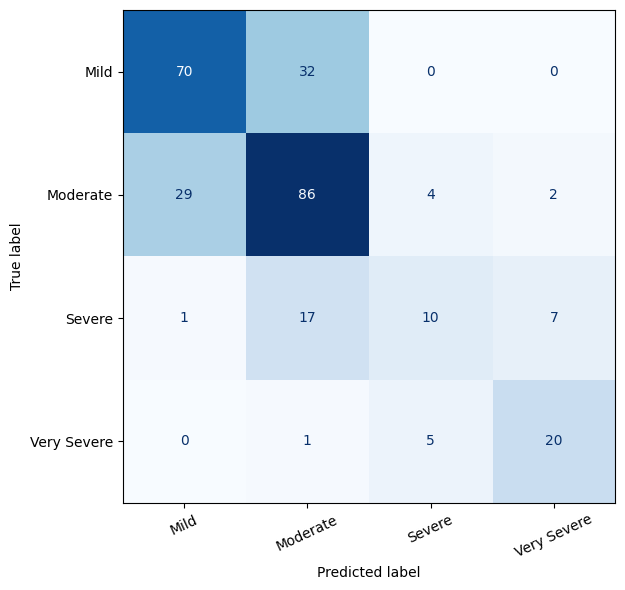

In [14]:
def evaluasi(y, pred):
    report = classification_report(y, pred, labels=LABELS, output_dict=True, zero_division=0)
    return {'accuracy': accuracy_score(y, pred), 'macro_f1': report['macro avg']['f1-score'], 'precision_macro': report['macro avg']['precision'], 'recall_macro': report['macro avg']['recall'], **{f'precision_{k}': report[str(k)]['precision'] for k in LABELS}, **{f'recall_{k}': report[str(k)]['recall'] for k in LABELS}, **{f'f1_{k}': report[str(k)]['f1-score'] for k in LABELS}}

X_test = muat_fitur(df_test)
y_test = df_test["level"].to_numpy(dtype=int)
with threadpool_limits(limits=1):
    prediksi_test = model_final.predict(X_test)

hasil_test = evaluasi(y_test, prediksi_test)
metrik = pd.DataFrame([hasil_test], index=["Testing"])
display(metrik[["accuracy", "macro_f1", "precision_macro", "recall_macro"]].round(4))
metrik.to_csv(OUTPUT_DIR / "metrik_testing.csv", index=False)

laporan = classification_report(
    y_test, prediksi_test, labels=LABELS, target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
laporan = pd.DataFrame(laporan).T
display(laporan.round(4))
laporan.to_csv(OUTPUT_DIR / "classification_report_testing.csv")

prediksi = df_test[["row_id", "file_name", "level", "severity", "sha256_pixels"]].copy()
prediksi["predicted_level"] = prediksi_test
prediksi["predicted_severity"] = [CLASS_MAP[int(k)] for k in prediksi_test]
prediksi.to_csv(OUTPUT_DIR / "prediksi_testing.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
cm = ConfusionMatrixDisplay.from_predictions(
    y_test, prediksi_test, labels=LABELS, display_labels=CLASS_NAMES,
    cmap="Blues", colorbar=False, xticks_rotation=25, ax=ax,
)
ax.grid(False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_testing.png", dpi=150)
plt.show()
pd.DataFrame(cm.confusion_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    OUTPUT_DIR / "confusion_matrix_testing.csv"
)

metadata_model["test_metrics"] = hasil_test
(OUTPUT_DIR / "metadata_model.json").write_text(
    json.dumps(metadata_model, indent=2), encoding="utf-8"
)

## 11. Memakai model tersimpan untuk menghasilkan severity

Foto melewati preprocessing dan ekstraksi fitur yang sama dengan training.
Level 0 = Mild, 1 = Moderate, 2 = Severe, 3 = Very Severe.
Contoh di bawah memakai satu gambar test untuk mengecek fungsi inference;
metrik tetap berasal dari evaluasi seluruh test pada langkah sebelumnya.

In [1]:
contoh_id = int(df_test.iloc[0]["row_id"])
with threadpool_limits(limits=1):
    hasil_contoh = prediksi_gambar_baru(data[contoh_id]["image"], MODEL_PATH, CONFIG_PATH)
assert hasil_contoh["level"] == int(prediksi_test[0])
print("Hasil prediksi:", hasil_contoh)

# Untuk foto milik sendiri, ganti path berikut lalu hilangkan tanda komentar.
hasil_baru = prediksi_gambar_baru("tes_jerawat_22.png", MODEL_PATH, CONFIG_PATH)
print(hasil_baru)

NameError: name 'df_test' is not defined

## 12. Pemeriksaan kesamaan dengan hasil lama (opsional)

Jika folder `hasil_dermascan_optimasi` tersedia, periksa bahwa konfigurasi fitur,
manifest split, prediksi test, dan probabilitas model sama dengan referensi.
Model lama hanya dibaca untuk verifikasi setelah model baru selesai dibuat;
tidak digunakan untuk melatih, memilih parameter, atau menggantikan model baru.
Jika folder referensi tidak tersedia, pelatihan dan prediksi tetap dapat dijalankan.

In [16]:
REFERENSI_DIR = Path("hasil_dermascan_optimasi")
berkas_referensi = [
    REFERENSI_DIR / "dermascan_classic.joblib",
    REFERENSI_DIR / "feature_config.json",
    REFERENSI_DIR / "prediksi_testing.csv",
    *[REFERENSI_DIR / "audit" / f"manifest_{nama}.csv" for nama in splits],
]
if all(berkas.exists() for berkas in berkas_referensi):
    config_lama = json.loads((REFERENSI_DIR / "feature_config.json").read_text(encoding="utf-8"))
    assert FEATURE_CONFIG == config_lama, "Konfigurasi fitur berbeda."
    for nama, tabel in splits.items():
        lama = pd.read_csv(REFERENSI_DIR / "audit" / f"manifest_{nama}.csv")
        for kolom in ["row_id", "level", "sha256_pixels"]:
            np.testing.assert_array_equal(tabel[kolom].to_numpy(), lama[kolom].to_numpy())

    prediksi_lama = pd.read_csv(REFERENSI_DIR / "prediksi_testing.csv")
    np.testing.assert_array_equal(df_test["row_id"], prediksi_lama["row_id"])
    np.testing.assert_array_equal(prediksi_test, prediksi_lama["predicted_level"])
    model_lama = joblib.load(REFERENSI_DIR / "dermascan_classic.joblib")
    assert model_final.get_params() == model_lama.get_params()
    with threadpool_limits(limits=1):
        np.testing.assert_array_equal(
            model_final.predict_proba(X_test), model_lama.predict_proba(X_test)
        )
    print("SAMA: konfigurasi fitur, split, parameter, prediksi, dan probabilitas test.")
else:
    print("Folder referensi tidak lengkap/tidak tersedia; pemeriksaan opsional dilewati.")

SAMA: konfigurasi fitur, split, parameter, prediksi, dan probabilitas test.


Notebook ini mempertahankan metode model sebelumnya. Hasil aktual ditampilkan
dari eksekusi, bukan diisi dengan angka target. Pada lingkungan referensi,
hasil sebelumnya adalah accuracy 65,49% dan macro F1 61,50% pada 284 gambar test.
Kesamaan hasil diperiksa menggunakan sel opsional di atas. Kesamaan byte berkas
joblib bukan syarat karena informasi serialisasi dapat berbeda.

## Hasil verifikasi lokal

Semua sel komputasi dijalankan berurutan pada data gambar asli lokal; sel instalasi dilewati karena versi paket sudah sesuai. Audit, split, seluruh fitur training, parameter, struktur pohon, serta probabilitas dan label prediksi sama persis dengan model referensi. Model hasil pelatihan disimpan di `hasil_dermascan_histgb/dermascan_classic.joblib`.

Hasil test: **accuracy 65,49%, macro F1 61,50%, precision macro 63,71%**. Cabang unduhan Hugging Face dan runtime Google Colab belum diuji. Rincian pemeriksaan terdapat pada `hasil_dermascan_histgb/verifikasi_notebook.json`.

Berkas model `.joblib` juga identik byte demi byte dengan referensi (SHA-256 sama).